# dbt, from an empty folder to a tested report

Day 2, before Lab 2.3 · CPU only. You build a small dbt project file by file and read every piece of SQL dbt
generates from it, so nothing in Lab 2.3's big project is magic. §9, the dbt tests Lab 2.4 uses, opens
session D2_4.

**The question:** how much delivered product revenue came from each store city? The rows are invented and small
enough to check by hand (SAR, without delivery fees).

**Rhythm:** 🤔 predict → run → 🔍 read. The ▶ players replay what dbt just did, one step at a time.

**Exercises (✏️):** uncomment the template (`Ctrl+/`), replace every `___`, delete the two `YOUR CODE HERE` lines,
then run the cell and the check after it (✅ = right). Answers: `solutions/tools/dbt.ipynb`.

**Contents** · 🎯 walked in class (minutes) · ➕ at your own pace, like the ✏️ exercises not done in class · core ≈ 27'
- [ ] 1 · Raw data: what dbt does not load · run before class
- [ ] 2 · The problem: three SQL files, run by hand · 🎯 4'
- [ ] 3 · The mental model: a graph of `SELECT`s · 🎯 2'
- [ ] 4 · A project, a profile and its sources · 🎯 2'
- [ ] 5 · Hello world: a `SELECT` becomes a view · 🎯 3'
- [ ] 6 · `ref()` builds a graph, and the graph sets the order · 🎯 5', Ex. 1–2 filled in together
- [ ] 7 · Materializations: view, table, incremental; break one on purpose · 🎯 7' 7a–b · ➕ 7c–d
- [ ] 8 · Macros: write an expression once · 🎯 2' (Lab 2.3 calls a macro)
- [ ] 9 · Tests: a build that succeeds is not a correct build · **opens D2_4**: 🎯 10' §9, 9a–c · ➕ 9d
- [ ] 10 · Lineage, documentation, and one more model of your own · 🎯 1'
- [ ] 11 · Back to the map · 🎯 1'

🎓 **Instructor notes** (solution notebook only)

- Walked in class so far in about 70'. Now split over two sessions: **D2_3** = §2–8, 10–11, core ≈ 27' (🎯 in the
  contents; 7c–d are ➕); **D2_4 opens with §9** (10': tests, 9a–c; 9d is ➕), then `tools/pandera`. Run the
  notebook down to §9 before D2_4 (a few minutes). Lab 2.3 §3 applies 7b to the real fact without re-teaching it.
- §6: fill in Exercises 1–2 together (the room calls out the blanks). Every later cell needs `stg_stores` and
  `mart_city_sales`, so they can't be left for later. The other exercises are ➕.
- In class, run the cells of a ➕ section without stopping on them: later cells may use what they build.
- §9's warn / contract / unit-test cells teach the mechanisms Lab 2.4 uses, on different cases: Lab 2.4 writes a
  `relationships` test with `severity: warn`, breaks a contract with a type change, and unit-tests mobile numbers.
- Every `dbt(...)` call takes a few seconds in process; a full run of this notebook is a few minutes.

## 1 · Raw data: what dbt does not load

Run from `labs/` (`uv run jupyter lab`) or in Colab.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "duckdb>=1.4", "dbt-core>=1.10,<2", "dbt-duckdb>=1.11"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import json
import textwrap
import duckdb
from IPython.display import display
import de_utils as U
import de_viz as V

# Rerunning THIS cell starts the lab again from an empty folder (it only deletes this lab's own outputs).
OUT = U.lab_dir("tools_dbt", reset=True)
PROJ = OUT / "qafila_intro"
PROJ.mkdir()
DB = OUT / "qafila_intro.duckdb"
print("Empty project folder:", PROJ, "| files:", list(PROJ.iterdir()))


def write_file(relative_path, content):
    path = PROJ / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(content).strip() + "\n", encoding="utf-8")
    print("Wrote", relative_path)


def sql(query):
    # Each query opens and closes its own connection, so the database is free when dbt opens it.
    with duckdb.connect(str(DB)) as connection:
        return connection.sql(query).df()


def execute_sql(statement):
    with duckdb.connect(str(DB)) as connection:
        connection.execute(statement)

Empty project folder: C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_dbt\qafila_intro | files: []


You are here: dbt **transforms** inside the warehouse (silver in `staging/`, gold in `marts/`) and **tests** what it
built; the documentation and lineage come from the same project.

In [2]:
V.platform_map(tool="dbt")

**Vocabulary:** database = the DuckDB file · schema = a namespace inside it (`raw`) · table = stored rows · view = a
stored query, run on every read.

This cell plays the **ingestion step** (dlt in Lab 1.3) and loads three raw tables. dbt never loads data.

In [3]:
RAW_SQL = """
CREATE SCHEMA raw;
CREATE TABLE raw.stores (store_id VARCHAR, city VARCHAR);
INSERT INTO raw.stores VALUES ('RUH-04', 'Riyadh'), ('JED-03', 'Jeddah');

CREATE TABLE raw.orders (order_id BIGINT, store_id VARCHAR, status VARCHAR, updated_at TIMESTAMP);
INSERT INTO raw.orders VALUES
    (101, 'RUH-04', 'delivered', '2026-09-20 09:00:00'),
    (102, 'JED-03', 'delivered', '2026-09-20 10:00:00'),
    (103, 'JED-03', 'cancelled', '2026-09-20 11:00:00');

CREATE TABLE raw.order_items (
    order_id BIGINT, line_no INTEGER, quantity INTEGER, unit_price DECIMAL(12,2), discount DECIMAL(12,2)
);
INSERT INTO raw.order_items VALUES
    (101, 1, 1, 33.46, 0.00),
    (101, 2, 2, 121.20, 0.00),
    (102, 1, 1, 33.65, 0.00),
    (103, 1, 1, 12.00, 0.00);
"""
execute_sql(RAW_SQL)
display(sql("SELECT * FROM raw.orders ORDER BY order_id"))
display(sql("SELECT * FROM raw.order_items ORDER BY order_id, line_no"))

,order_id,store_id,status,updated_at
0,101,RUH-04,delivered,2026-09-20 09:00:00
1,102,JED-03,delivered,2026-09-20 10:00:00
2,103,JED-03,cancelled,2026-09-20 11:00:00


,order_id,line_no,quantity,unit_price,discount
0,101,1,1,33.46,0.0
1,101,2,2,121.20,0.0
2,102,1,1,33.65,0.0
3,103,1,1,12.00,0.0


🤔 **Predict** · What should the report say for Riyadh and for Jeddah? Our revenue: delivered lines with a
positive quantity, worth `quantity * unit_price - discount`.

🔍 Riyadh (order 101): 33.46 + 2 × 121.20 = **275.86**. Jeddah: **33.65** (order 103 is cancelled).

## 2 · The problem: three SQL files, run by hand

Before dbt, let's build the report the way many teams start: a folder of SQL files, each one creating a table from
the one before.

`clean_orders.sql` → `order_sales.sql` → `city_sales.sql`

We run them on a scratch copy of the raw data (an in-memory database), so the real one stays untouched.

In [4]:
FILES = {
    "clean_orders.sql": """
        CREATE OR REPLACE TABLE orders_clean AS
        SELECT order_id, store_id, status FROM raw.orders
    """,
    "order_sales.sql": """
        CREATE OR REPLACE TABLE order_sales AS
        SELECT o.order_id, o.store_id, o.status, i.quantity * i.unit_price - i.discount AS net_amount
        FROM raw.order_items i JOIN orders_clean o ON i.order_id = o.order_id
    """,
    "city_sales.sql": """
        CREATE OR REPLACE TABLE city_sales AS
        SELECT s.city, SUM(f.net_amount) AS revenue_sar
        FROM order_sales f JOIN raw.stores s ON f.store_id = s.store_id
        WHERE f.status = 'delivered'
        GROUP BY s.city
    """,
}


def run_by_hand(con, *names):
    for name in names:
        con.execute(FILES[name])
        print("ran", name)

🤔 **Predict** · A scheduler runs every `.sql` file in the folder, in alphabetical order, on a new database. What happens?

In [5]:
by_hand = duckdb.connect()   # in memory
by_hand.execute(RAW_SQL)
try:
    run_by_hand(by_hand, *sorted(FILES))
except duckdb.Error as e:
    print("❌", str(e).splitlines()[0])

❌ Catalog Error: Table with name order_sales does not exist!


🔍 `city_sales.sql` comes first alphabetically, and `order_sales` doesn't exist yet. The files depend on each other,
but nothing in the folder says so: the order lives in someone's head. Run them in the right order:

In [6]:
run_by_hand(by_hand, "clean_orders.sql", "order_sales.sql", "city_sales.sql")
by_hand.sql("FROM city_sales ORDER BY city").df()

ran clean_orders.sql
ran order_sales.sql
ran city_sales.sql


,city,revenue_sar
0,Jeddah,33.65
1,Riyadh,275.86


Correct. Now the source changes: order 103 is **delivered** after all. The manager asks for a fresh report, so you
rerun the report file.

🤔 **Predict** · Does Jeddah now include order 103's 12 SAR?

In [7]:
by_hand.execute("UPDATE raw.orders SET status = 'delivered' WHERE order_id = 103")
run_by_hand(by_hand, "city_sales.sql")
stale = by_hand.sql("SELECT revenue_sar FROM city_sales WHERE city = 'Jeddah'").fetchall()[0][0]
U.check(float(stale) == 33.65, "no error, and Jeddah is still 33.65: the report was rebuilt from old tables")

ran city_sales.sql
✅ no error, and Jeddah is still 33.65: the report was rebuilt from old tables


🔍 The report reran, but it read `order_sales`, which was built from `orders_clean`, which was built **before** the
update. Follow order 103 through the tables:

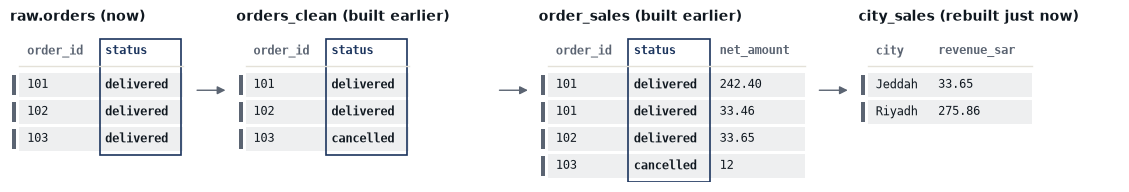

In [8]:
V.table_steps([
    {"title": "raw.orders (now)", "df": by_hand.sql("SELECT order_id, status FROM raw.orders ORDER BY 1").df(),
     "new": ["status"]},
    {"title": "orders_clean (built earlier)", "df": by_hand.sql("SELECT order_id, status FROM orders_clean ORDER BY 1").df(),
     "new": ["status"]},
    {"title": "order_sales (built earlier)",
     "df": by_hand.sql("SELECT order_id, status, net_amount FROM order_sales ORDER BY 1").df(), "new": ["status"]},
    {"title": "city_sales (rebuilt just now)", "df": by_hand.sql("FROM city_sales ORDER BY city").df()},
])

To get it right you had to know that the report depends on `order_sales`, which depends on `orders_clean`, and rerun
all three in that order. With 3 files that's annoying; with 300 it's how wrong numbers reach a dashboard.

Look also at what every file repeats: `CREATE OR REPLACE TABLE ... AS`, around the only part that matters, the
`SELECT`. Here is the same `order_sales` as a **dbt model**:

In [9]:
by_hand.close()
V.sql_steps([
    ("By hand · order_sales.sql", FILES["order_sales.sql"]),
    ("With dbt · models/order_sales.sql", """
        SELECT o.order_id, o.store_id, o.status, i.quantity * i.unit_price - i.discount AS net_amount
        FROM {{ source('raw', 'order_items') }} i JOIN {{ ref('orders_clean') }} o ON i.order_id = o.order_id
    """, "no CREATE: only the SELECT. ref() says what it reads"),
])

Each pain above has a dbt answer, and each one has a section below:

| By hand | With dbt | § |
|---|---|---|
| you must know the run order | `ref()` and `source()` become a graph; dbt runs it in order | 6 |
| after a change, you must know what to rerun | `--select orders_clean+` = it and everything downstream | 6, 7 |
| `CREATE OR REPLACE` in every file | one setting: view, table or incremental | 5, 7 |
| the same expression copied in many files | a macro, written once | 8 |
| nobody checks the result | tests that run with the build | 9 |
| a renamed column breaks a dashboard | a contract on the model's columns and types | 9 |

dbt doesn't run the SQL itself: it generates it and sends it to a database, here DuckDB. And it doesn't load data:
the raw tables come from ingestion.

🤔 **Predict** · In dbt, you edit a model file and save it. Has the database changed?

🔍 No. Files are instructions; only a dbt command (`dbt run`, `dbt build`) changes the database.

## 3 · The mental model: a graph of `SELECT`s

```
 models/*.sql  (one SELECT each,           dbt reads them all     dbt renders the Jinja      the warehouse
 source() and ref() inside)           →    and draws the graph →  and sends the SQL in   →   (DuckDB here) runs
 _sources.yml, _models.yml (tests)         target/manifest.json   graph order, then tests    every statement
 └────────────── you write this ──────────────┘ └──────────────────── dbt does this ────────────────────┘
```

| You declare | dbt does |
|---|---|
| a `SELECT` in a file named after the result | wraps it in `CREATE VIEW` / `CREATE TABLE` / `INSERT`, under a temporary name, then swaps it in |
| what it reads: `source()` for raw tables, `ref()` for models | draws the graph, builds parents before children, independent branches in parallel |
| how to store it: `view`, `table`, `incremental` | writes the right SQL for this database (the **adapter**) |
| what must be true: tests, contracts | runs each test right after its model, and skips what depends on a failure |
| descriptions | documentation and lineage, from the same files |

dbt is a **compiler and a runner**, not a database: it never stores a row, and it never loads data. The model design
(what one row means, which rows count as revenue) is still yours (Lab 2.2).

## 4 · A project, a profile and its sources

Two files make a folder a dbt project:
- `dbt_project.yml`: what the project is, and how to build its models;
- `profiles.yml`: which database runs the SQL. Its name must match the project's `profile:`.

In [10]:
write_file("dbt_project.yml", """
name: qafila_intro
version: '1.0.0'
config-version: 2
profile: qafila_intro
model-paths: [models]
test-paths: [tests]
models:
  qafila_intro:
    staging:
      +schema: staging
      +materialized: view
    marts:
      +schema: marts
      +materialized: table
""")
write_file("profiles.yml", f"""
qafila_intro:
  target: dev
  outputs:
    dev:
      type: duckdb
      path: '{DB.as_posix()}'
      schema: analytics
      threads: 1
""")
(PROJ / "models").mkdir(exist_ok=True)
(PROJ / "tests").mkdir(exist_ok=True)

Wrote dbt_project.yml
Wrote profiles.yml


**`dbt_project.yml`**, key by key:

| Key | Means |
|---|---|
| `name` | the project's name (it reappears under `models:`) |
| `version` | your project's version: a label, nothing checks it |
| `config-version: 2` | the format of this file; always 2 |
| `profile` | which entry of `profiles.yml` to connect with |
| `model-paths`, `test-paths` | the folders holding models and tests (these are the defaults, written out) |
| `models:` → `qafila_intro:` → `staging:` | settings for every model in `models/staging/` |
| `+materialized` | how those models are stored: `view`, `table`, ... (§7) |
| `+schema` | the schema they go to, **appended** to the profile's: `analytics` + `staging` → `analytics_staging` |

The `+` marks a setting, so dbt doesn't read `materialized` as a folder name. A model can override its folder's
settings with `{{ config(...) }}` at the top of its file (§7).

**`profiles.yml`**:

| Key | Means |
|---|---|
| `qafila_intro` | the profile's name, matching `profile:` above |
| `target: dev` | which output to use unless you pass `--target prod` |
| `outputs:` → `dev:` | one block per environment (dev, prod, ...) |
| `type: duckdb` | the adapter: which database dbt generates SQL for (package `dbt-duckdb`) |
| `path` | the DuckDB file (a server database would have `host`, `user`, `password` instead) |
| `schema: analytics` | where dbt writes its models (see below) |
| `threads: 1` | how many models dbt may build at the same time |

**Why `schema: analytics`?** The database will hold two kinds of tables: the ones ingestion loads (`raw`) and the
ones dbt builds. Keeping them in different schemas gives each a single owner. Ingestion writes to `raw`, and dbt only
reads it. dbt writes only under `analytics`, so a `dbt run` can never overwrite source data, and anything under
`analytics` can always be rebuilt from `raw`. The name itself is our choice: `analytics`, `dbt` or `transform` are
all common.

The folder settings then split it further, so the schema tells readers what they're looking at:

| Schema | Holds | Who reads it |
|---|---|---|
| `raw` | source tables, as loaded | ingestion writes; dbt reads |
| `analytics_staging` | cleaned copies, one per source | other models |
| `analytics_marts` | facts and reports | analysts, dashboards |

It's also what makes environments safe. Each developer's `dev` output gets their own schema (`schema: dev_sara`
gives `dev_sara_staging`, `dev_sara_marts`), and only the `prod` output writes to `analytics`. Everyone runs the same
project without touching each other's tables or production.

**Not only DuckDB.** `type` picks an **adapter**, a separate package that teaches dbt one database's SQL. The same
project can run on, for example:

| Database | Package | Connection keys |
|---|---|---|
| DuckDB, MotherDuck | `dbt-duckdb` | `path` (a file, or `md:` for the cloud) |
| PostgreSQL | `dbt-postgres` | `host`, `port`, `user`, `password`, `dbname` |
| Snowflake | `dbt-snowflake` | `account`, `user`, `role`, `warehouse`, `database` |
| BigQuery | `dbt-bigquery` | `project`, `dataset`, `method` (how to log in) |
| Databricks, Spark | `dbt-databricks`, `dbt-spark` | `host`, `http_path`, `token` |

Redshift, Trino, ClickHouse, SQL Server and others have adapters too. Typically one profile has an output per
environment, here a local DuckDB for development and a shared Postgres for production:

```yaml
qafila:
  target: dev                       # the default
  outputs:
    dev:
      type: duckdb
      path: qafila_dev.duckdb
      schema: analytics
    prod:
      type: postgres
      host: warehouse.qafila.internal
      port: 5432
      user: dbt_prod
      password: "{{ env_var('DBT_PROD_PASSWORD') }}"   # read from the environment, never written in the file
      dbname: analytics
      schema: analytics
      threads: 8                    # a server can build 8 models at once
```

What that gives you:
- **one project, several databases:** `dbt build` builds in dev; `dbt build --target prod` builds the same models in
  production. dbt writes the `CREATE` statements in each database's dialect. Your `SELECT`s must still use SQL that
  the database understands;
- **no secrets in the repository:** `env_var()` reads passwords and tokens from environment variables;
- **models that know where they run:** `{{ target.name }}` is `dev` or `prod`, e.g. to read only the last 7 days of
  data while developing.

`dbt("debug")` below is `dbt debug --profiles-dir .` in a terminal. It checks the connection and builds nothing.

In [11]:
from dbt.cli.main import dbtRunner


def dbt(*args, expect_success=True, log=True):
    flags = ["--no-use-colors", "--no-send-anonymous-usage-stats"] + ([] if log else ["--log-level", "none"])
    # --log-path keeps dbt.log inside the project; without it dbt writes logs/ next to the notebook.
    paths = ["--project-dir", str(PROJ), "--profiles-dir", str(PROJ), "--log-path", str(PROJ / "logs")]
    result = dbtRunner().invoke([*flags, *args, *paths])
    command = "dbt " + " ".join(args)
    if expect_success and not result.success:
        raise RuntimeError(command + " failed: see the log above") from result.exception
    if log:
        U.check(result.success == expect_success, command + (" succeeded" if result.success else " failed, as expected"))
    return result


def generated(kind, path):
    """A SQL file dbt wrote: kind is "compiled" (the rendered SELECT) or "run" (the SQL it executed)."""
    return (PROJ / "target" / kind / "qafila_intro" / path).read_text(encoding="utf-8")


dbt("debug")

18:29:52  Running with dbt=1.12.6


18:29:52  dbt version: 1.12.6


18:29:52  python version: 3.13.11


18:29:52  python path: C:\Users\nayef\Desktop\courses\data-engineering\labs\.venv\Scripts\python.exe


18:29:52  os info: Windows-11-10.0.26300-SP0


...

18:29:52  Registered adapter: duckdb=1.11.0


18:29:58    Connection test: [OK connection ok]



18:29:58  All checks passed!


✅ dbt debug succeeded


dbtRunnerResult(success=True, exception=None, result=True)

🔍 `All checks passed!` If not: a missing adapter, a profile name that doesn't match, a wrong path, or the database
open in another program.

**Sources** give the raw tables a name that models use: `source('qafila_raw', 'orders')`. In `_sources.yml`:
`version: 2` is the format of dbt's YAML files; `name: qafila_raw` is the first argument of `source()`;
`schema: raw` is where the tables really are; each `tables: - name` is a second argument.

🤔 **Predict** · After declaring them, how many tables does the database hold?

In [12]:
write_file("models/staging/_sources.yml", """
version: 2
sources:
  - name: qafila_raw
    schema: raw
    tables:
      - name: orders
      - name: order_items
      - name: stores
""")
print(dbt("ls", "--resource-type", "source", "--output", "name", log=False).result)
display(sql("SELECT table_schema, table_name, table_type FROM information_schema.tables ORDER BY 1, 2"))
U.check(len(sql("FROM information_schema.tables")) == 3, "still the same 3 raw tables: a source declaration loads nothing")

Wrote models/staging/_sources.yml


['qafila_raw.order_items', 'qafila_raw.orders', 'qafila_raw.stores']


,table_schema,table_name,table_type
0,raw,order_items,BASE TABLE
1,raw,orders,BASE TABLE
2,raw,stores,BASE TABLE


✅ still the same 3 raw tables: a source declaration loads nothing


🔍 Still three: a source only **describes** data that something else loaded.

## 5 · Hello world: a `SELECT` becomes a view

The file name `stg_orders.sql` becomes the view's name; its folder makes it a view. (`stg_` = staging: one model per
source table, rename and cast, no business logic.)

🤔 **Predict** · Does `dbt compile` create the view?

In [13]:
write_file("models/staging/stg_orders.sql", """
SELECT order_id, store_id, status, updated_at
FROM {{ source('qafila_raw', 'orders') }}
""")
dbt("compile", "--select", "stg_orders")
V.sql_steps([
    ("We write · models/staging/stg_orders.sql", (PROJ / "models/staging/stg_orders.sql").read_text()),
    ("dbt compile · target/compiled/…/stg_orders.sql", generated("compiled", "models/staging/stg_orders.sql"),
     "Jinja replaced by the table's full name: database.schema.table"),
])

Wrote models/staging/stg_orders.sql
18:30:01  Running with dbt=1.12.6


18:30:01  Registered adapter: duckdb=1.11.0


18:30:02  [WARNING]: Configuration paths exist in your dbt_project.yml file which do not apply to any resources.
There are 1 unused configuration paths:
- models.qafila_intro.marts


18:30:03  Found 1 model, 3 sources, 500 macros


18:30:03  


18:30:03  Concurrency: 1 threads (target='dev')


18:30:03  


Compiled node 'stg_orders' is:
SELECT order_id, store_id, status, updated_at
FROM "qafila_intro"."raw"."orders"


✅ dbt compile --select stg_orders succeeded


In [14]:
U.check(sql("FROM information_schema.tables WHERE table_name = 'stg_orders'").empty,
        "compile wrote SQL to target/compiled/, but created nothing in the database")

✅ compile wrote SQL to target/compiled/, but created nothing in the database


🔍 No. `{{ ... }}` is **Jinja**: dbt fills it in before any SQL exists, and `compile` stops there. Use it to read the
SQL dbt will send.

🤔 **Predict** · We wrote no `CREATE VIEW` and no `CREATE SCHEMA`. What will `dbt run` do?

18:30:03  Running with dbt=1.12.6


18:30:03  Registered adapter: duckdb=1.11.0


18:30:03  [WARNING]: Configuration paths exist in your dbt_project.yml file which do not apply to any resources.
There are 1 unused configuration paths:
- models.qafila_intro.marts


18:30:03  Found 1 model, 3 sources, 500 macros


18:30:03  


...

18:30:04  


18:30:04  Completed successfully


18:30:04  


18:30:04  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt run --select stg_orders succeeded


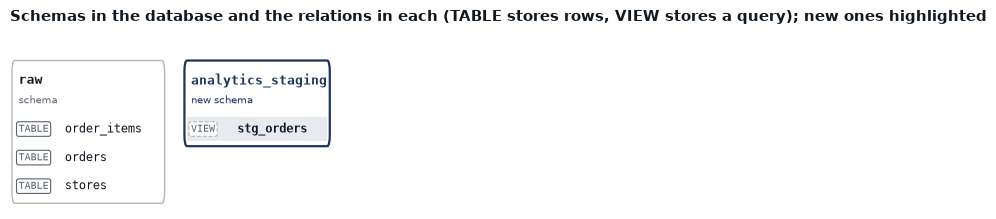

In [15]:
tables_before = sql("SELECT table_schema, table_name, table_type FROM information_schema.tables")
schemas_before = set(sql("SELECT schema_name FROM information_schema.schemata").schema_name)
dbt("run", "--select", "stg_orders")
tables_after = sql("SELECT table_schema, table_name, table_type FROM information_schema.tables")
schemas_after = set(sql("SELECT schema_name FROM information_schema.schemata").schema_name)
V.database_map(tables_after, before=tables_before)

In [16]:
V.sql_steps([
    ("We write · stg_orders.sql", (PROJ / "models/staging/stg_orders.sql").read_text()),
    ("dbt compiles", generated("compiled", "models/staging/stg_orders.sql")),
    ("dbt runs · target/run/…/stg_orders.sql", generated("run", "models/staging/stg_orders.sql"),
     "the same SELECT, wrapped in the SQL of a view"),
])

In [17]:
U.check("analytics_staging" in schemas_after - schemas_before, "dbt created the missing schema analytics_staging")
U.check(sql("SELECT table_type FROM information_schema.tables WHERE table_name = 'stg_orders'").table_type[0] == "VIEW",
        "stg_orders is a view: its folder's default")

✅ dbt created the missing schema analytics_staging
✅ stg_orders is a view: its folder's default


🔍 dbt picked the schema, created it, wrapped our `SELECT` in `create view`, and sent it to DuckDB. It builds under a
temporary name (`__dbt_tmp`) and renames at the end, so nobody reads a half-built model.

## 6 · `ref()` builds a graph, and the graph sets the order

`stg_order_items` gives each line an id (`101-2`) and its `net_amount`: one row per line.

In [18]:
write_file("models/staging/stg_order_items.sql", """
SELECT
    CAST(order_id AS VARCHAR) || '-' || CAST(line_no AS VARCHAR) AS order_line_id,
    order_id, line_no, quantity, unit_price, discount,
    quantity * unit_price - discount AS net_amount
FROM {{ source('qafila_raw', 'order_items') }}
""")

Wrote models/staging/stg_order_items.sql


✏️ **Exercise 1** (🎯 together in class) · Write `models/staging/stg_stores.sql`: `store_id` and `city`, read with
`source()`.
- **Check yourself:** 2 rows, and the compiled SQL contains `"raw"."stores"`.

In [19]:
# Template:
# write_file("models/staging/stg_stores.sql", """
# SELECT store_id, city
# FROM {{ source('___', '___') }}
# """)
write_file("models/staging/stg_stores.sql", """
SELECT store_id, city
FROM {{ source('qafila_raw', 'stores') }}
""")

Wrote models/staging/stg_stores.sql


In [20]:
dbt("run", "--select", "stg_stores")
U.check(len(sql("FROM analytics_staging.stg_stores")) == 2, "stg_stores has the 2 stores")
U.check('"raw"."stores"' in generated("compiled", "models/staging/stg_stores.sql"), "source() resolved to raw.stores")

18:30:04  Running with dbt=1.12.6


18:30:04  Registered adapter: duckdb=1.11.0


18:30:05  [WARNING]: Configuration paths exist in your dbt_project.yml file which do not apply to any resources.
There are 1 unused configuration paths:
- models.qafila_intro.marts


18:30:05  Found 3 models, 3 sources, 500 macros


18:30:05  


...

18:30:05  


18:30:05  Completed successfully


18:30:05  


18:30:05  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt run --select stg_stores succeeded
✅ stg_stores has the 2 stores
✅ source() resolved to raw.stores


The **fact**: one row per line, with its order's store and status. Models read other models with `ref()`. The fact
keeps every status; the report decides what counts.

In [21]:
FACT_SELECT = """
SELECT
    i.order_line_id, i.order_id, i.line_no,
    o.store_id, o.status, o.updated_at,
    i.quantity, i.net_amount
FROM {{ ref('stg_order_items') }} i
JOIN {{ ref('stg_orders') }} o ON i.order_id = o.order_id
WHERE i.quantity > 0
"""
write_file("models/marts/fct_order_items.sql", FACT_SELECT)

Wrote models/marts/fct_order_items.sql


✏️ **Exercise 2** (🎯 together in class) · Write `models/marts/mart_city_sales.sql`: join the fact to the stores (both
with `ref()`), keep delivered lines, and sum `net_amount` per city as `revenue_sar`.
- **Check yourself:** Riyadh 275.86, Jeddah 33.65.

In [22]:
# Template:
# write_file("models/marts/mart_city_sales.sql", """
# SELECT s.city, SUM(f.net_amount) AS revenue_sar
# FROM {{ ref('___') }} f
# JOIN {{ ref('___') }} s ON f.store_id = s.store_id
# WHERE f.status = '___'
# GROUP BY s.city
# """)
write_file("models/marts/mart_city_sales.sql", """
SELECT s.city, SUM(f.net_amount) AS revenue_sar
FROM {{ ref('fct_order_items') }} f
JOIN {{ ref('stg_stores') }} s ON f.store_id = s.store_id
WHERE f.status = 'delivered'
GROUP BY s.city
""")

Wrote models/marts/mart_city_sales.sql


🤔 **Predict** · `+mart_city_sales` = the report **and everything it needs**. In what order will dbt build them?

In [23]:
dbt("run", "--select", "+mart_city_sales")
display(sql("SELECT * FROM analytics_marts.mart_city_sales ORDER BY city"))

18:30:05  Running with dbt=1.12.6


18:30:05  Registered adapter: duckdb=1.11.0


18:30:06  Found 5 models, 3 sources, 500 macros


18:30:06  


18:30:06  Concurrency: 1 threads (target='dev')


...

18:30:07  Completed successfully


18:30:07  


18:30:07  Done. PASS=5 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=5


✅ dbt run --select +mart_city_sales succeeded


,city,revenue_sar
0,Jeddah,33.65
1,Riyadh,275.86


In [24]:
city = lambda name: round(float(sql(f"SELECT revenue_sar FROM analytics_marts.mart_city_sales WHERE city = '{name}'").revenue_sar[0]), 2)
U.check(city("Riyadh") == 275.86, "Riyadh matches the hand calculation")
U.check(city("Jeddah") == 33.65, "cancelled order 103 contributes nothing to Jeddah")

✅ Riyadh matches the hand calculation
✅ cancelled order 103 contributes nothing to Jeddah


▶ **Watch it run.** `V.animate_dbt` replays the last command from `target/manifest.json` (the graph) and
`target/run_results.json` (what ran). Press **Play**, or **Next**. (Buttons do nothing? Run the cell again.)

In [25]:
V.animate_dbt(PROJ)

🔍 Each `ref()` is an arrow. dbt reads them all first, then runs each model after its parents. The staging views
don't depend on each other, so any order works (with more threads, in parallel).

🧪 **Experiment** · A model that names the fact's table directly, without `ref()`. What are its parents?

In [26]:
write_file("models/marts/mart_hardcoded.sql", "SELECT COUNT(*) AS n_lines FROM analytics_marts.fct_order_items")
print("+mart_city_sales →", dbt("ls", "--select", "+mart_city_sales", "--output", "name", log=False).result)
print("+mart_hardcoded  →", dbt("ls", "--select", "+mart_hardcoded", "--output", "name", log=False).result)
(PROJ / "models/marts/mart_hardcoded.sql").unlink()

Wrote models/marts/mart_hardcoded.sql


+mart_city_sales → ['fct_order_items', 'mart_city_sales', 'stg_order_items', 'stg_orders', 'stg_stores', 'qafila_raw.order_items', 'qafila_raw.orders', 'qafila_raw.stores']


+mart_hardcoded  → ['mart_hardcoded']


🔍 None. dbt may build it before the fact, `fct_order_items+` won't refresh it, and the lineage loses it. Always
`ref()` models and `source()` raw tables.

| `--select` | Selects |
|---|---|
| `fct_order_items` | that model |
| `+fct_order_items` | it and its parents |
| `fct_order_items+` | it and its children |
| `staging` | the `models/staging/` folder |

The folders are **layers**, and each answers a different question. They are how dbt organises the platform's
**silver** and **gold** zones; **bronze** is the `raw` schema, which dbt only reads. In Lab 2.3's project:

| Folder | Qafila example (Lab 2.3) | Its job | Zone |
|---|---|---|---|
| `staging/` | `stg_orders` | one model per source table: rename, cast, derive the order date; no business logic | silver |
| `intermediate/` | `int_payments_per_order` | reshape for reuse: payment attempts → one row per order | silver |
| `marts/` | `fct_order_items`, `fct_orders`, `dim_customers` | facts and dimensions at a declared grain | gold |
| `marts/` | `mart_daily_city_sales` | a report for one business question | gold |
| `quarantine/` | `qrn_order_items` | the rows kept out of the facts, each with its reason | beside silver |

Watch the names: `stg_` models are **cleaned** (silver), although a warehouse's "stage" area usually means the
landed copy (bronze). And the payments are reduced to one row per order **before** they meet the orders, so several
payment attempts can't multiply an order's amount (the fan-out of Lab 2.2).

## 7 · Materializations: view, table, incremental; break one on purpose

| `materialized=` | Stores | The work happens |
|---|---|---|
| `view` | a query | on every read |
| `table` | rows, rebuilt each run | at `dbt run`, over all rows |
| `incremental` | rows, updated each run | at `dbt run`, over the rows its filter selects |
| `ephemeral` | nothing (pasted into its readers as a CTE) | inside the readers |

### 7a · A view sees a change at once; a table needs a rebuild

🤔 **Predict** · Order 103 is now delivered in the source. Which shows it first: the view or the table?

In [27]:
execute_sql("UPDATE raw.orders SET status = 'delivered', updated_at = '2026-09-22 09:00:00' WHERE order_id = 103")
display(sql("""
    SELECT 'stg_orders (view)' AS model, status FROM analytics_staging.stg_orders WHERE order_id = 103
    UNION ALL
    SELECT 'fct_order_items (table)', status FROM analytics_marts.fct_order_items WHERE order_id = 103
"""))

,model,status
0,stg_orders (view),delivered
1,fct_order_items (table),cancelled


In [28]:
U.check(sql("SELECT status FROM analytics_staging.stg_orders WHERE order_id = 103").status[0] == "delivered",
        "the view re-reads the source every time: it already sees the update")
U.check(sql("SELECT status FROM analytics_marts.fct_order_items WHERE order_id = 103").status[0] == "cancelled",
        "the table still holds the rows of its last build")

✅ the view re-reads the source every time: it already sees the update
✅ the table still holds the rows of its last build


🔍 A view is never stale but pays on every read; a table is fast but frozen at its last build. `fct_order_items+`
rebuilds the fact and its children:

In [29]:
dbt("run", "--select", "fct_order_items+")
U.check(city("Jeddah") == 45.65, "after the rebuild, Jeddah includes order 103's 12 SAR")
V.animate_dbt(PROJ)

18:30:08  Running with dbt=1.12.6


18:30:08  Registered adapter: duckdb=1.11.0


18:30:09  Found 5 models, 3 sources, 500 macros


18:30:09  


18:30:09  Concurrency: 1 threads (target='dev')


...

18:30:09  


18:30:09  Completed successfully


18:30:09  


18:30:09  Done. PASS=2 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=2


✅ dbt run --select fct_order_items+ succeeded
✅ after the rebuild, Jeddah includes order 103's 12 SAR


### 7b · An incremental model processes only the rows that changed

It loads everything on the first run, then only the rows its filter selects. Three choices are ours:
- **filter:** orders updated at most 1 day before the newest one loaded (the **overlap** catches late changes);
- **`unique_key`:** how to recognize a row already in the table;
- **`delete+insert`:** delete the stored rows whose key comes back, then insert the new versions.

In the model below:

| Part | Means |
|---|---|
| `{{ config(...) }}` | settings for this model only; they override the folder's `+materialized: table` |
| `materialized='incremental'` | keep the table between runs and add to it |
| `unique_key='order_line_id'` | the column that identifies a row |
| `incremental_strategy='delete+insert'` | how the new rows are written into the table (7c lists the others) |
| `{% if is_incremental() %} ... {% endif %}` | the filter, left out on the first run and with `--full-refresh` |
| `{{ this }}` | the model's own table, so the filter can ask what's already loaded |

In [30]:
INCREMENTAL_SQL = """
{{ config(materialized='incremental', unique_key='order_line_id', incremental_strategy='delete+insert') }}
""" + FACT_SELECT + """
{% if is_incremental() %}
  AND o.updated_at >= (
    SELECT COALESCE(MAX(updated_at), TIMESTAMP '1970-01-01') - INTERVAL 1 DAY
    FROM {{ this }}
  )
{% endif %}
"""
write_file("models/marts/fct_order_items_incremental.sql", INCREMENTAL_SQL)
dbt("run", "--select", "+fct_order_items_incremental")
U.check(len(sql("FROM analytics_marts.fct_order_items_incremental")) == 4, "the first run loads all four lines")

Wrote models/marts/fct_order_items_incremental.sql
18:30:09  Running with dbt=1.12.6


18:30:10  Registered adapter: duckdb=1.11.0


18:30:10  Found 6 models, 3 sources, 500 macros


18:30:10  


18:30:10  Concurrency: 1 threads (target='dev')


...

18:30:11  


18:30:11  Completed successfully


18:30:11  


18:30:11  Done. PASS=3 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=3


✅ dbt run --select +fct_order_items_incremental succeeded
✅ the first run loads all four lines


Now order 101 is refunded.

🤔 **Predict** · The newest `updated_at` loaded is 22 Sept 09:00. Which lines will the next run reprocess?

We compile first and run that `SELECT` ourselves: it returns exactly what dbt will hand to `delete+insert`.

In [31]:
execute_sql("UPDATE raw.orders SET status = 'refunded', updated_at = '2026-09-25 12:00:00' WHERE order_id = 101")
before = sql("SELECT * FROM analytics_marts.fct_order_items_incremental ORDER BY order_line_id")
cutoff = sql("SELECT MAX(updated_at) - INTERVAL 1 DAY AS c FROM analytics_marts.fct_order_items_incremental").c[0]
dbt("compile", "--select", "fct_order_items_incremental")
candidates = sql(generated("compiled", "models/marts/fct_order_items_incremental.sql"))
dbt("run", "--select", "fct_order_items_incremental")
after = sql("SELECT * FROM analytics_marts.fct_order_items_incremental ORDER BY order_line_id")
display(after)

18:30:11  Running with dbt=1.12.6


18:30:11  Registered adapter: duckdb=1.11.0


18:30:12  Found 6 models, 3 sources, 500 macros


18:30:12  


18:30:12  Concurrency: 1 threads (target='dev')


...

18:30:13  Completed successfully


18:30:13  


18:30:13  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt run --select fct_order_items_incremental succeeded


,order_line_id,order_id,line_no,store_id,status,updated_at,quantity,net_amount
0,101-1,101,1,RUH-04,refunded,2026-09-25 12:00:00,1,33.46
1,101-2,101,2,RUH-04,refunded,2026-09-25 12:00:00,2,242.40
2,102-1,102,1,JED-03,delivered,2026-09-20 10:00:00,1,33.65
3,103-1,103,1,JED-03,delivered,2026-09-22 09:00:00,1,12.00


▶ **Watch it run.** Left: the model's `SELECT`. Right: the incremental table.

In [32]:
V.animate_incremental(
    all_rows=sql(generated("compiled", "models/marts/fct_order_items.sql")), candidates=candidates, before=before,
    key="order_line_id", cutoff=cutoff, show=["order_line_id", "status", "updated_at", "net_amount"])

In [33]:
U.check(sorted(candidates.order_line_id) == ["101-1", "101-2", "103-1"], "3 lines in the window: 101's two, and 103's")
U.check(len(after) == 4 and after.order_line_id.is_unique, "still 4 lines, one per order_line_id: no duplicates")
U.check(set(after[after.order_id == 101].status) == {"refunded"}, "both of order 101's lines are refunded")
dbt("run", "--select", "fct_order_items_incremental")
U.check(sql("SELECT * FROM analytics_marts.fct_order_items_incremental ORDER BY order_line_id").equals(after),
        "running again over the same data changes nothing: reprocessing the overlap is safe")

✅ 3 lines in the window: 101's two, and 103's


✅ still 4 lines, one per order_line_id: no duplicates
✅ both of order 101's lines are refunded
18:30:13  Running with dbt=1.12.6


18:30:13  Registered adapter: duckdb=1.11.0


18:30:13  Found 6 models, 3 sources, 500 macros


18:30:13  


...

18:30:14  


18:30:14  Completed successfully


18:30:14  


18:30:14  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt run --select fct_order_items_incremental succeeded
✅ running again over the same data changes nothing: reprocessing the overlap is safe


🔍 103-1 was reprocessed unchanged: that's the overlap, and it's harmless (replaced, not duplicated). 102-1 was
outside the window and never read. All the SQL of that run:

In [34]:
DELETE_INSERT_RUN = generated("run", "models/marts/fct_order_items_incremental.sql")
V.sql_steps([
    ("We write · fct_order_items_incremental.sql", INCREMENTAL_SQL),
    ("dbt compiles (is_incremental() is true)", generated("compiled", "models/marts/fct_order_items_incremental.sql"),
     "the filter is in, and {{ this }} is the model's own table"),
    ("dbt runs · target/run/…", DELETE_INSERT_RUN,
     "the SELECT went into a temporary table first; then delete + insert"),
])

`unique_key` matches rows; it doesn't **check** that they're unique. Only a test does (§9).

### 7c · Other strategies, and one side by side ➕

`incremental_strategy` decides how the batch the filter selected is written into the table:

| Strategy | What one run does | Typical use |
|---|---|---|
| `append` | inserts the batch; no key, nothing is replaced | events that never change (clicks, logs) |
| `delete+insert` | deletes the stored rows whose key comes back, then inserts the batch | this lab; DuckDB's default |
| `merge` | one `MERGE INTO`: updates the rows whose key matches, inserts the new keys | default on Snowflake, BigQuery, Databricks |
| `insert_overwrite` | replaces every partition (e.g. a day) the batch touches | partitioned tables on BigQuery, Spark |
| `microbatch` | splits the work into time slices (e.g. one per day), each rerunnable on its own | large event tables |

Which ones you can use depends on the adapter. Let's try `merge` once on the same model, then switch back.

🤔 **Predict** · Same filter, same `unique_key`, same data; only the strategy changes. Does the table change?

In [35]:
MERGE_SQL = INCREMENTAL_SQL.replace("incremental_strategy='delete+insert'", "incremental_strategy='merge'")
write_file("models/marts/fct_order_items_incremental.sql", MERGE_SQL)
dbt("run", "--select", "fct_order_items_incremental")
U.check(sql("SELECT * FROM analytics_marts.fct_order_items_incremental ORDER BY order_line_id").equals(after),
        "same table: the strategy changes how the rows are written, not which rows end up there")
V.sql_steps([
    ("delete+insert · target/run/…", DELETE_INSERT_RUN, "two statements: DELETE the keys that came back, then INSERT"),
    ("merge · target/run/…", generated("run", "models/marts/fct_order_items_incremental.sql"),
     "one statement: UPDATE on a match, INSERT otherwise"),
])
write_file("models/marts/fct_order_items_incremental.sql", INCREMENTAL_SQL)   # back to delete+insert for the lab

Wrote models/marts/fct_order_items_incremental.sql
18:30:14  Running with dbt=1.12.6


18:30:14  Registered adapter: duckdb=1.11.0


18:30:15  Found 6 models, 3 sources, 500 macros


18:30:15  


18:30:15  Concurrency: 1 threads (target='dev')


...

18:30:15  


18:30:15  Completed successfully


18:30:15  


18:30:15  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt run --select fct_order_items_incremental succeeded
✅ same table: the strategy changes how the rows are written, not which rows end up there
Wrote models/marts/fct_order_items_incremental.sql


🔍 Same rows, different SQL. A practical plus of `merge`: it can update only some columns of a matched row
(`merge_update_columns=['status', 'updated_at']` in the `config()`); `delete+insert` always replaces the whole row.

Every strategy writes only what the filter selected. So what happens when a row changes and the filter doesn't
select it?

### 7d · 🧪 Break it on purpose: a change the filter can't see ➕

🤔 **Predict** · Line 102-1 gets a 2 SAR discount. The line changes; its order's `updated_at` doesn't. After
rebuilding both facts, which one has the discount?

In [36]:
execute_sql("UPDATE raw.order_items SET discount = 2.00 WHERE order_id = 102 AND line_no = 1")
dbt("run", "--select", "fct_order_items", "fct_order_items_incremental")
line_102 = sql("""
    SELECT 'fct_order_items (table)' AS model, net_amount FROM analytics_marts.fct_order_items WHERE order_line_id = '102-1'
    UNION ALL
    SELECT 'fct_order_items_incremental', net_amount FROM analytics_marts.fct_order_items_incremental WHERE order_line_id = '102-1'
""")
line_102

18:30:15  Running with dbt=1.12.6


18:30:16  Registered adapter: duckdb=1.11.0


18:30:16  Found 6 models, 3 sources, 500 macros


18:30:16  


18:30:16  Concurrency: 1 threads (target='dev')


...

18:30:16  Completed successfully


18:30:16  


18:30:16  Done. PASS=2 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=2


✅ dbt run --select fct_order_items fct_order_items_incremental succeeded


,model,net_amount
0,fct_order_items (table),31.65
1,fct_order_items_incremental,33.65


In [37]:
U.check(line_102.net_amount.tolist() == [31.65, 33.65], "the table has the discount, the incremental model missed it")

✅ the table has the discount, the incremental model missed it


🔍 No error, and the incremental model stays wrong: its filter only watches `orders.updated_at`. The filter defines
what you can miss:

| Change | Found? |
|---|---|
| an order updated inside the overlap | yes |
| a line changed, its order untouched (just now) | no |
| a late record, older than the overlap | no |
| a deleted source row | no |
| a fix to the model's logic | only for new rows |

Fixes: watch the right timestamp, widen the overlap, or rebuild with `--full-refresh` (the `SELECT` over all rows).

In [38]:
dbt("run", "--select", "fct_order_items_incremental", "--full-refresh")
U.check(sql("SELECT net_amount FROM analytics_marts.fct_order_items_incremental WHERE order_line_id = '102-1'")
        .net_amount[0] == 31.65, "the full refresh picked up the discount")
dbt("run", "--select", "fct_order_items+")
U.check(city("Jeddah") == 43.65, "and the report shows it: 31.65 + 12.00 for Jeddah, nothing for refunded Riyadh")

18:30:16  Running with dbt=1.12.6


18:30:17  Registered adapter: duckdb=1.11.0


18:30:17  Found 6 models, 3 sources, 500 macros


18:30:17  


18:30:17  Concurrency: 1 threads (target='dev')


...

18:30:18  


18:30:18  Completed successfully


18:30:18  


18:30:18  Done. PASS=2 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=2


✅ dbt run --select fct_order_items+ succeeded
✅ and the report shows it: 31.65 + 12.00 for Jeddah, nothing for refunded Riyadh


## 8 · Macros: write an expression once

`quantity * unit_price - discount` is our revenue definition; copies of it drift apart. A **macro** is named Jinja
that returns SQL text. dbt pastes it in before the SQL reaches the database.

In [39]:
write_file("macros/net_amount.sql", """
{% macro net_amount(quantity, unit_price, discount) -%}
    ({{ quantity }} * {{ unit_price }} - {{ discount }})
{%- endmacro %}
""")

Wrote macros/net_amount.sql


✏️ **Exercise 3** · In `stg_order_items.sql`, replace the expression with a call: `{{ net_amount('quantity', ...) }}`
(column names as strings).
- **Check yourself:** the compiled SQL contains `(quantity * unit_price - discount)`; the report doesn't change.

In [40]:
# Template:
# write_file("models/staging/stg_order_items.sql", """
# SELECT
#     CAST(order_id AS VARCHAR) || '-' || CAST(line_no AS VARCHAR) AS order_line_id,
#     order_id, line_no, quantity, unit_price, discount,
#     {{ ___('quantity', 'unit_price', '___') }} AS net_amount
# FROM {{ source('qafila_raw', 'order_items') }}
# """)
write_file("models/staging/stg_order_items.sql", """
SELECT
    CAST(order_id AS VARCHAR) || '-' || CAST(line_no AS VARCHAR) AS order_line_id,
    order_id, line_no, quantity, unit_price, discount,
    {{ net_amount('quantity', 'unit_price', 'discount') }} AS net_amount
FROM {{ source('qafila_raw', 'order_items') }}
""")

Wrote models/staging/stg_order_items.sql


In [41]:
dbt("run", "--select", "stg_order_items+")
V.sql_steps([
    ("We write · stg_order_items.sql", (PROJ / "models/staging/stg_order_items.sql").read_text()),
    ("dbt compiles", generated("compiled", "models/staging/stg_order_items.sql"), "the macro call became its SQL"),
])
U.check("(quantity * unit_price - discount)" in generated("compiled", "models/staging/stg_order_items.sql"),
        "the macro expanded into the expression")
U.check(city("Jeddah") == 43.65, "same revenue as before: the definition moved, it didn't change")

18:30:19  Running with dbt=1.12.6


18:30:19  Registered adapter: duckdb=1.11.0


18:30:19  Found 6 models, 3 sources, 501 macros


18:30:19  


18:30:19  Concurrency: 1 threads (target='dev')


...

18:30:20  


18:30:20  Completed successfully


18:30:20  


18:30:20  Done. PASS=4 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=4


✅ dbt run --select stg_order_items+ succeeded
✅ the macro expanded into the expression
✅ same revenue as before: the definition moved, it didn't change


## 9 · Tests: a build that succeeds is not a correct build

A **test** is a `SELECT` of the rows that **break** a rule: 0 rows = pass. **Generic** tests (`unique`, `not_null`,
...) are declared in YAML; **singular** tests are SQL files in `tests/`.

In `_models.yml`, each `- name:` is a model; `description` goes into the documentation (§10); under `columns:`,
`data_tests: [unique, not_null]` attaches those two tests to that column. A test that takes settings is written as a
mapping: `accepted_values` gets the list of allowed values under `arguments:`, so a new or misspelled `status` fails.

In [42]:
write_file("models/marts/_models.yml", """
version: 2
models:
  - name: fct_order_items
    description: One row per order line with a positive quantity; keeps the order's status.
    columns:
      - name: order_line_id
        data_tests: [unique, not_null]
      - name: status
        data_tests:
          - accepted_values:
              arguments:
                values: [placed, delivered, cancelled,
                         refunded, failed_delivery]
  - name: fct_order_items_incremental
    columns:
      - name: order_line_id
        data_tests: [unique, not_null]
  - name: mart_city_sales
    description: Delivered product revenue in SAR by store city, excluding delivery fees.
    columns:
      - name: city
        data_tests: [unique, not_null]
""")
write_file("tests/assert_fact_stores_exist.sql", """
-- every line's store must exist in stg_stores: return the lines whose store doesn't
SELECT f.order_line_id, f.store_id
FROM {{ ref('fct_order_items') }} f
LEFT JOIN {{ ref('stg_stores') }} s ON f.store_id = s.store_id
WHERE s.store_id IS NULL
""")
dbt("build")

Wrote models/marts/_models.yml
Wrote tests/assert_fact_stores_exist.sql
18:30:20  Running with dbt=1.12.6


18:30:20  Registered adapter: duckdb=1.11.0


18:30:22  Found 6 models, 8 data tests, 3 sources, 501 macros


18:30:22  


18:30:22  Concurrency: 1 threads (target='dev')


...

18:30:24  Completed successfully


18:30:24  


18:30:24  Done. PASS=14 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=14


✅ dbt build succeeded


dbtRunnerResult(success=True, exception=None, result=RunExecutionResult(results=[RunResult(status=<RunStatus.Success: 'success'>, timing=[TimingInfo(name='compile', started_at=datetime.datetime(2026, 10, 21, 18, 30, 22, 750774), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 22, 760542)), TimingInfo(name='execute', started_at=datetime.datetime(2026, 10, 21, 18, 30, 22, 762850), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 22, 824915))], thread_id='Thread-61 (worker)', execution_time=0.07929110527038574, adapter_response={'_message': 'OK'}, message='OK', failures=None, node=ModelNode(database='qafila_intro', schema='analytics_staging', name='stg_order_items', resource_type=<NodeType.Model: 'model'>, package_name='qafila_intro', path='staging\\stg_order_items.sql', original_file_path='models\\staging\\stg_order_items.sql', unique_id='model.qafila_intro.stg_order_items', fqn=['qafila_intro', 'staging', 'stg_order_items'], alias='stg_order_items', checksum=FileHash(name='sha2

`dbt build` = run + test along the graph: a model, its tests, then its children. What `[unique]` turns into:

In [43]:
UNIQUE_TEST = "models/marts/_models.yml/unique_fct_order_items_order_line_id.sql"
V.sql_steps([
    ("We write · _models.yml", "columns:\n  - name: order_line_id\n    data_tests: [unique, not_null]"),
    ("dbt generates · target/compiled/…/unique_fct_order_items_order_line_id.sql", generated("compiled", UNIQUE_TEST),
     "the keys that appear more than once"),
])
display(sql(generated("compiled", UNIQUE_TEST)))

,unique_field,n_records


🤔 **Predict** · Line 102-1 is now delivered twice. Which test fails? Is the report rebuilt? Is the duplicate
already in the fact?

In [44]:
execute_sql("INSERT INTO raw.order_items SELECT * FROM raw.order_items WHERE order_id = 102 AND line_no = 1")
dbt("build", "--select", "+mart_city_sales", expect_success=False)
statuses = {r["unique_id"].split(".")[2]: r["status"]
            for r in json.loads((PROJ / "target/run_results.json").read_text(encoding="utf-8"))["results"]}
statuses

18:30:24  Running with dbt=1.12.6


18:30:24  Registered adapter: duckdb=1.11.0


18:30:24  Found 6 models, 8 data tests, 3 sources, 501 macros


18:30:24  


18:30:24  Concurrency: 1 threads (target='dev')


...

18:30:25    compiled code at target\compiled\qafila_intro\models\marts\_models.yml\unique_fct_order_items_order_line_id.sql


18:30:25  


18:30:25  Done. PASS=7 WARN=0 ERROR=1 SKIP=3 NO-OP=0 REUSED=0 TOTAL=11


✅ dbt build --select +mart_city_sales failed, as expected


{'stg_order_items': 'success',
 'stg_orders': 'success',
 'stg_stores': 'success',
 'fct_order_items': 'success',
 'accepted_values_fct_order_items_status__placed__delivered__cancelled__refunded__failed_delivery': 'pass',
 'assert_fact_stores_exist': 'pass',
 'not_null_fct_order_items_order_line_id': 'pass',
 'unique_fct_order_items_order_line_id': 'fail',
 'mart_city_sales': 'skipped',
 'not_null_mart_city_sales_city': 'skipped',
 'unique_mart_city_sales_city': 'skipped'}

▶ **Watch it run.** Follow the red.

In [45]:
V.animate_dbt(PROJ)

In [46]:
display(sql(generated("compiled", UNIQUE_TEST)))
U.check(statuses["unique_fct_order_items_order_line_id"] == "fail", "the unique test found the duplicated line")
U.check(statuses["mart_city_sales"] == "skipped", "the report was skipped: dbt doesn't build on a failed test")
U.check(len(sql("FROM analytics_marts.fct_order_items")) == 5, "but the fact already holds the 5 rows, duplicate included")

,unique_field,n_records
0,102-1,2


✅ the unique test found the duplicated line
✅ the report was skipped: dbt doesn't build on a failed test
✅ but the fact already holds the 5 rows, duplicate included


🔍 The report was **skipped** and keeps its last good rows. But the fact was built **before** its test, so the
duplicate is already in the database. A test stops what comes after; it doesn't undo what came before.

Fix the source, then rebuild:

In [47]:
execute_sql("CREATE OR REPLACE TABLE raw.order_items AS SELECT DISTINCT * FROM raw.order_items")
dbt("build")
U.check(len(sql("FROM analytics_marts.fct_order_items")) == 4, "the repaired fact has 4 lines again")

18:30:25  Running with dbt=1.12.6


18:30:25  Registered adapter: duckdb=1.11.0


18:30:26  Found 6 models, 8 data tests, 3 sources, 501 macros


18:30:26  


18:30:26  Concurrency: 1 threads (target='dev')


...

18:30:27  Completed successfully


18:30:27  


18:30:27  Done. PASS=14 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=14


✅ dbt build succeeded


✅ the repaired fact has 4 lines again


Tests check rules, not numbers. Last check: recompute the report straight from the raw tables.

In [48]:
expected = sql("""
    SELECT s.city, SUM(i.quantity * i.unit_price - i.discount) AS revenue_sar
    FROM raw.orders o
    JOIN raw.order_items i ON o.order_id = i.order_id
    JOIN raw.stores s ON o.store_id = s.store_id
    WHERE o.status = 'delivered' AND i.quantity > 0
    GROUP BY s.city ORDER BY s.city
""")
actual = sql("SELECT * FROM analytics_marts.mart_city_sales ORDER BY city")
display(actual)
U.check(actual.equals(expected), "the report reconciles with a direct calculation from the raw tables")

,city,revenue_sar
0,Jeddah,43.65


✅ the report reconciles with a direct calculation from the raw tables


✏️ **Exercise 4** · Write the singular test `tests/assert_city_revenue_nonnegative.sql`: the rows of
`mart_city_sales` whose `revenue_sar` is negative or `NULL`.
- **Check yourself:** `dbt test` on it passes.

In [49]:
# Template:
# write_file("tests/assert_city_revenue_nonnegative.sql", """
# SELECT * FROM {{ ref('___') }}
# WHERE ___
# """)
write_file("tests/assert_city_revenue_nonnegative.sql", """
SELECT * FROM {{ ref('mart_city_sales') }}
WHERE revenue_sar < 0 OR revenue_sar IS NULL
""")

Wrote tests/assert_city_revenue_nonnegative.sql


In [50]:
result = dbt("test", "--select", "assert_city_revenue_nonnegative")
U.check([r.status for r in result.result] == ["pass"], "dbt ran your test, and no city breaks the rule")

18:30:27  Running with dbt=1.12.6


18:30:27  Registered adapter: duckdb=1.11.0


18:30:28  Found 6 models, 9 data tests, 3 sources, 501 macros


18:30:28  


18:30:28  Concurrency: 1 threads (target='dev')


...

18:30:28  


18:30:28  Completed successfully


18:30:28  


18:30:28  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt test --select assert_city_revenue_nonnegative succeeded
✅ dbt ran your test, and no city breaks the rule


### 9a · Warn or error: decide what a failure means

The source team adds a status: order 101 is now `refunded`. Someone wrote a test on `stg_orders` that only knows
three statuses.

🤔 **Predict** · `dbt build` of the report. With the default severity (`error`), what happens to the fact and the
report?

In [51]:
STATUS_TEST = """
version: 2
models:
  - name: stg_orders
    columns:
      - name: status
        data_tests:
          - accepted_values:
              arguments:
                values: [placed, delivered, cancelled]
"""
write_file("models/staging/_staging.yml", STATUS_TEST)
dbt("build", "--select", "+mart_city_sales", expect_success=False)
statuses = {r["unique_id"].split(".")[2]: r["status"]
            for r in json.loads((PROJ / "target/run_results.json").read_text(encoding="utf-8"))["results"]}
U.check(statuses["fct_order_items"] == "skipped" and statuses["mart_city_sales"] == "skipped",
        "error: the failing test on stg_orders skipped the fact and the report")

Wrote models/staging/_staging.yml


18:30:28  Running with dbt=1.12.6


18:30:28  Registered adapter: duckdb=1.11.0


18:30:28  Found 6 models, 10 data tests, 3 sources, 501 macros


18:30:28  


...

18:30:29    compiled code at target\compiled\qafila_intro\models\staging\_staging.yml\accepted_values_stg_orders_status__placed__delivered__cancelled.sql


18:30:29  


18:30:29  Done. PASS=3 WARN=0 ERROR=1 SKIP=9 NO-OP=0 REUSED=0 TOTAL=13


✅ dbt build --select +mart_city_sales failed, as expected


✅ error: the failing test on stg_orders skipped the fact and the report


🔍 One unknown value stopped the whole report. Sometimes that's right (a duplicated key in a fact). Here the new
status is a known source change that someone should look at, not a reason to stop. `severity: warn` records the
failure and lets the build go on:

In [52]:
write_file("models/staging/_staging.yml", STATUS_TEST + """              config:
                severity: warn
""")
dbt("build", "--select", "+mart_city_sales")
statuses = {r["unique_id"].split(".")[2]: r["status"]
            for r in json.loads((PROJ / "target/run_results.json").read_text(encoding="utf-8"))["results"]}
U.check([s for name, s in statuses.items() if name.startswith("accepted_values_stg_orders")] == ["warn"],
        "warn: the failure is recorded...")
U.check(statuses["mart_city_sales"] == "success", "...and the report is built")
(PROJ / "models/staging/_staging.yml").unlink()

Wrote models/staging/_staging.yml
18:30:29  Running with dbt=1.12.6


18:30:29  Registered adapter: duckdb=1.11.0


18:30:30  Found 6 models, 10 data tests, 3 sources, 501 macros


18:30:30  


18:30:30  Concurrency: 1 threads (target='dev')


...

18:30:31  


18:30:31    compiled code at target\compiled\qafila_intro\models\staging\_staging.yml\accepted_values_stg_orders_status__placed__delivered__cancelled.sql


18:30:31  


18:30:31  Done. PASS=12 WARN=1 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=13


✅ dbt build --select +mart_city_sales succeeded
✅ warn: the failure is recorded...
✅ ...and the report is built


Three responses, three jobs:

| Response | What happens | Qafila example |
|---|---|---|
| **error** | the test fails and `dbt build` skips everything downstream | a duplicated fact key |
| **warn** | the failure is recorded, the build continues; someone must follow it up | a new source status, an erased customer |
| **quarantine** | a model routes the rejected rows to their own table, with a reason; the rest is published | non-positive quantities (`qrn_order_items`, Lab 2.3) |

Quarantine is not a test setting: it's a model whose `WHERE` is the opposite of the fact's. Rows in the fact plus
rows in quarantine should add up to the source.

### 9b · A contract: the columns consumers rely on

Tests check **values**. A dashboard also relies on the **shape** of a model: its column names and types. An enforced
**contract** declares them, and dbt refuses to build a model whose `SELECT` doesn't match, before it replaces the
table.

In [53]:
CONTRACT_YML = """
version: 2
models:
  - name: fct_order_items
    description: One row per order line with a positive quantity; keeps the order's status.
    columns:
      - name: order_line_id
        data_tests: [unique, not_null]
      - name: status
        data_tests:
          - accepted_values:
              arguments:
                values: [placed, delivered, cancelled,
                         refunded, failed_delivery]
  - name: fct_order_items_incremental
    columns:
      - name: order_line_id
        data_tests: [unique, not_null]
  - name: mart_city_sales
    description: Delivered product revenue in SAR by store city, excluding delivery fees.
    config:
      contract:
        enforced: true
    columns:
      - name: city
        data_type: varchar
        data_tests: [unique, not_null]
      - name: revenue_sar
        data_type: decimal(38,2)
"""
write_file("models/marts/_models.yml", CONTRACT_YML)
dbt("build", "--select", "mart_city_sales")

Wrote models/marts/_models.yml


18:30:31  Running with dbt=1.12.6


18:30:32  Registered adapter: duckdb=1.11.0


18:30:32  Found 6 models, 9 data tests, 3 sources, 501 macros


18:30:32  


...

18:30:32  Completed successfully


18:30:32  


18:30:32  Done. PASS=4 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=4


✅ dbt build --select mart_city_sales succeeded


dbtRunnerResult(success=True, exception=None, result=RunExecutionResult(results=[RunResult(status=<RunStatus.Success: 'success'>, timing=[TimingInfo(name='compile', started_at=datetime.datetime(2026, 10, 21, 18, 30, 32, 572929), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 32, 578715)), TimingInfo(name='execute', started_at=datetime.datetime(2026, 10, 21, 18, 30, 32, 579655), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 32, 724347))], thread_id='Thread-85 (worker)', execution_time=0.15424394607543945, adapter_response={'_message': 'OK'}, message='OK', failures=None, node=ModelNode(database='qafila_intro', schema='analytics_marts', name='mart_city_sales', resource_type=<NodeType.Model: 'model'>, package_name='qafila_intro', path='marts\\mart_city_sales.sql', original_file_path='models\\marts\\mart_city_sales.sql', unique_id='model.qafila_intro.mart_city_sales', fqn=['qafila_intro', 'marts', 'mart_city_sales'], alias='mart_city_sales', checksum=FileHash(name='sha256', che

A developer tidies the report and renames `revenue_sar` to `revenue`. The SQL is valid.

🤔 **Predict** · Does the build succeed? What does the dashboard see afterwards?

In [54]:
REPORT = (PROJ / "models/marts/mart_city_sales.sql").read_text(encoding="utf-8")
write_file("models/marts/mart_city_sales.sql", REPORT.replace("AS revenue_sar", "AS revenue"))
broken = dbt("build", "--select", "mart_city_sales", log=False, expect_success=False)
print([line for line in str(broken.result[0].message).splitlines() if "revenue" in line][:4])
U.check(not broken.success, "the contract stopped the build")
U.check(list(sql("FROM analytics_marts.mart_city_sales").columns) == ["city", "revenue_sar"],
        "and the table the dashboard reads still has revenue_sar")
write_file("models/marts/mart_city_sales.sql", REPORT)
dbt("build", "--select", "mart_city_sales")

Wrote models/marts/mart_city_sales.sql


['  | revenue     | DECIMAL(38,2)   |               | missing in contract   |', '  | revenue_sar |                 | DECIMAL(38,2) | missing in definition |']
✅ the contract stopped the build
✅ and the table the dashboard reads still has revenue_sar
Wrote models/marts/mart_city_sales.sql
18:30:34  Running with dbt=1.12.6


18:30:34  Registered adapter: duckdb=1.11.0


18:30:34  Found 6 models, 9 data tests, 3 sources, 501 macros


18:30:34  


...

18:30:35  Completed successfully


18:30:35  


18:30:35  Done. PASS=4 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=4


✅ dbt build --select mart_city_sales succeeded


dbtRunnerResult(success=True, exception=None, result=RunExecutionResult(results=[RunResult(status=<RunStatus.Success: 'success'>, timing=[TimingInfo(name='compile', started_at=datetime.datetime(2026, 10, 21, 18, 30, 35, 21201), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 35, 30297)), TimingInfo(name='execute', started_at=datetime.datetime(2026, 10, 21, 18, 30, 35, 31661), completed_at=datetime.datetime(2026, 10, 21, 18, 30, 35, 117082))], thread_id='Thread-93 (worker)', execution_time=0.0993802547454834, adapter_response={'_message': 'OK'}, message='OK', failures=None, node=ModelNode(database='qafila_intro', schema='analytics_marts', name='mart_city_sales', resource_type=<NodeType.Model: 'model'>, package_name='qafila_intro', path='marts\\mart_city_sales.sql', original_file_path='models\\marts\\mart_city_sales.sql', unique_id='model.qafila_intro.mart_city_sales', fqn=['qafila_intro', 'marts', 'mart_city_sales'], alias='mart_city_sales', checksum=FileHash(name='sha256', checksu

🔍 The mismatch table names the missing and the unexpected column, and nothing reached the database. Changing a
contract is a decision taken with the consumers (a new model version, Day 4), not a quiet edit. A contract checks
names and types, not values: a `revenue_sar` of -5 still fits it, which is why the tests stay.

### 9c · A unit test: check the logic on rows you choose

Data tests check today's data. A **unit test** gives a model a few input rows **you** write and compares its output
with the rows you expect, so it can test a case that today's data doesn't contain, like a discount on a line of
three.

In [55]:
write_file("models/staging/_unit_tests.yml", """
unit_tests:
  - name: net_amount_subtracts_the_discount
    model: stg_order_items
    given:
      - input: source('qafila_raw', 'order_items')
        rows:
          - {order_id: 1, line_no: 1, quantity: 2, unit_price: 10.00, discount: 0.00}
          - {order_id: 1, line_no: 2, quantity: 3, unit_price: 5.50, discount: 1.50}
    expect:
      rows:
        - {order_line_id: "1-1", net_amount: 20.00}
        - {order_line_id: "1-2", net_amount: 15.00}
""")
result = dbt("test", "--select", "test_type:unit")
U.check([r.status for r in result.result] == ["pass"], "the model computes 2 × 10 = 20 and 3 × 5.50 − 1.50 = 15")

Wrote models/staging/_unit_tests.yml
18:30:35  Running with dbt=1.12.6


18:30:35  Registered adapter: duckdb=1.11.0


18:30:36  Found 6 models, 9 data tests, 3 sources, 501 macros, 1 unit test


18:30:36  


18:30:36  Concurrency: 1 threads (target='dev')


...

18:30:36  


18:30:36  Completed successfully


18:30:36  


18:30:36  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


✅ dbt test --select test_type:unit succeeded
✅ the model computes 2 × 10 = 20 and 3 × 5.50 − 1.50 = 15


🧪 **Break it on purpose** · Someone "simplifies" the macro and drops the discount.

🤔 **Predict** · Which tests notice: the data tests (`unique`, `not_null`, the singular ones) or the unit test?

In [56]:
MACRO = (PROJ / "macros/net_amount.sql").read_text(encoding="utf-8")
write_file("macros/net_amount.sql", MACRO.replace(" - {{ discount }}", ""))
data_tests = dbt("build", "--exclude", "test_type:unit", log=False)
unit = dbt("test", "--select", "test_type:unit", log=False, expect_success=False)
print("data tests:", sorted({str(r.status) for r in data_tests.result if r.node.resource_type == "test"}))
print("unit test: ", [str(r.status) for r in unit.result])
U.check(data_tests.success and not unit.success, "only the unit test fails: the data still looks fine")
U.check(city("Jeddah") == 45.65, "and the report is wrong by the 2 SAR discount (43.65 before)")
write_file("macros/net_amount.sql", MACRO)
dbt("build")
U.check(city("Jeddah") == 43.65, "macro restored: the report is right again")

Wrote macros/net_amount.sql


data tests: ['pass']
unit test:  ['fail']
✅ only the unit test fails: the data still looks fine
✅ and the report is wrong by the 2 SAR discount (43.65 before)
Wrote macros/net_amount.sql
18:30:39  Running with dbt=1.12.6


18:30:39  Registered adapter: duckdb=1.11.0


18:30:40  Found 6 models, 9 data tests, 3 sources, 501 macros, 1 unit test


18:30:40  


...

18:30:41  


18:30:41  Completed successfully


18:30:41  


18:30:41  Done. PASS=16 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=16


✅ dbt build succeeded
✅ macro restored: the report is right again


🔍 The data tests pass: no key is duplicated, no value is null, no revenue is negative. The numbers are simply wrong
by every discount. Only a test that knows the expected answer catches a wrong rule. A plain `dbt build` runs each
unit test **before** its model, so with the unit test in place this rule would never have reached the table.

### 9d · Where each check belongs ➕

| Where | Check | Catches | In this course |
|---|---|---|---|
| a file or DataFrame at the door | Pandera schema | bad values before they are loaded | Lab 2.4 |
| the logic of a model | dbt unit test | a wrong rule, on rows you chose | §9c, Lab 2.4 |
| the tables just built | dbt data tests | broken keys, nulls, unknown values, orphans | §9, Labs 2.3–2.4 |
| the model's interface | dbt contract | renamed or retyped columns | §9b, Lab 2.4 |
| production, after release | freshness, volume, Unknown rate | changes nobody tested for | Day 4 |

**Before a change is merged**, CI (continuous integration) builds it in its own schema and runs these checks. dbt can
build only what the change touches:

```
dbt build --select state:modified+ --defer --state prod-artifacts/
```

`state:modified+` = the models whose files differ from production's `manifest.json` (in `prod-artifacts/`), and their
children; `--defer` reads the unchanged parents from production instead of rebuilding them. A real CI job also needs
its own credentials and target schema.

## 10 · Lineage, documentation, and one more model of your own

`target/manifest.json` (the graph) and `target/run_results.json` (the last command) are what the players read.
Orchestrators read them too (Lab 4.1).

In [57]:
dbt("docs", "generate")
manifest = json.loads((PROJ / "target/manifest.json").read_text(encoding="utf-8"))
for name in ["fct_order_items", "mart_city_sales"]:
    print(name, "depends on:", manifest["nodes"][f"model.qafila_intro.{name}"]["depends_on"]["nodes"])
print("Documentation files:", [f for f in ["index.html", "manifest.json", "catalog.json"] if (PROJ / "target" / f).exists()])

18:30:41  Running with dbt=1.12.6


18:30:41  Registered adapter: duckdb=1.11.0


18:30:42  Found 6 models, 9 data tests, 3 sources, 501 macros, 1 unit test


18:30:42  


18:30:42  Concurrency: 1 threads (target='dev')


18:30:42  


18:30:42  Building catalog


18:30:43  Catalog written to C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_dbt\qafila_intro\target\catalog.json


✅ dbt docs generate succeeded
fct_order_items depends on: ['model.qafila_intro.stg_order_items', 'model.qafila_intro.stg_orders']
mart_city_sales depends on: ['model.qafila_intro.fct_order_items', 'model.qafila_intro.stg_stores']
Documentation files: ['index.html', 'manifest.json', 'catalog.json']


To browse the docs: `dbt docs serve --profiles-dir .` in a terminal, in the project folder (`Ctrl+C` stops it).

| Command | Does |
|---|---|
| `dbt debug` | checks the connection |
| `dbt compile` | renders the Jinja, builds nothing |
| `dbt run` | builds models |
| `dbt test` | tests what's built |
| `dbt build` | builds and tests, along the graph |
| `dbt ls` | lists what a selection selects |
| `dbt docs generate` | writes the documentation |
| `dbt run --full-refresh` | rebuilds incremental models from all rows (§7d) |
| `dbt test --select test_type:unit` | only the unit tests (§9c) |
| `dbt source freshness` | checks when each source last received data (Day 4) |

✏️ **Exercise 5** · Write `models/marts/mart_city_order_counts.sql`: delivered **orders** per city, as
`delivered_orders`, from `stg_orders` and `stg_stores`.
- **Check yourself:** one row: Jeddah, 2 (order 101 is refunded).

In [58]:
# Template:
# write_file("models/marts/mart_city_order_counts.sql", """
# SELECT s.city, ___ AS delivered_orders
# FROM {{ ref('___') }} o
# JOIN {{ ref('___') }} s ON o.store_id = s.store_id
# WHERE o.status = '___'
# GROUP BY s.city
# """)
write_file("models/marts/mart_city_order_counts.sql", """
SELECT s.city, COUNT(*) AS delivered_orders
FROM {{ ref('stg_orders') }} o
JOIN {{ ref('stg_stores') }} s ON o.store_id = s.store_id
WHERE o.status = 'delivered'
GROUP BY s.city
""")

Wrote models/marts/mart_city_order_counts.sql


In [59]:
dbt("build", "--select", "+mart_city_order_counts")
counts = sql("SELECT * FROM analytics_marts.mart_city_order_counts ORDER BY city")
display(counts)
U.check(counts.to_dict("records") == [{"city": "Jeddah", "delivered_orders": 2}], "Jeddah: 2 delivered orders, each counted once")
dbt("build")
print("Your complete project is in:", PROJ)

18:30:43  Running with dbt=1.12.6


18:30:43  Registered adapter: duckdb=1.11.0


18:30:43  Found 7 models, 9 data tests, 3 sources, 501 macros, 1 unit test


18:30:43  


18:30:43  Concurrency: 1 threads (target='dev')


...

18:30:46  


18:30:46  Completed successfully


18:30:46  


18:30:46  Done. PASS=17 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=17


✅ dbt build succeeded
Your complete project is in: C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_dbt\qafila_intro


## 11 · Back to the map

dbt **transforms** inside the warehouse (silver in `staging/` and `intermediate/`, gold in `marts/`), **tests**
what it built, and documents it; the warehouse runs the SQL.

In [60]:
V.platform_map(tool="dbt")

| | |
|---|---|
| **It does** | SQL `SELECT`s as a project in Git · the build order from `ref()` / `source()` · views, tables, incremental models · macros · data tests, unit tests, contracts · documentation and lineage (`manifest.json`) |
| **It doesn't** | load data (dlt, Lab 1.3) · store or compute anything itself (the warehouse does) · schedule runs (Dagster, Lab 4.1) · design the model for you (Lab 2.2) |
| **In this course** | Lab 2.3 builds the Qafila project (`dbt_qafila/`) · Lab 2.4 adds tests, a contract and a unit test · Lab 4.1 runs it from Dagster, one asset per model · Lab 4.2's contracts and freshness |
| **Managed equivalents** | dbt Cloud (the same project with scheduling, an IDE and CI) · SQLMesh / Tobiko Cloud · warehouse-native tools: Dataform (BigQuery), Snowflake Dynamic Tables, Databricks Lakeflow Declarative Pipelines |
| **Neighbours** | SQLMesh (similar models, with plans and virtual environments) · Dagster (orchestrates dbt, Lab 4.1) · Polars / Spark (transformations in Python instead of SQL) |

## Checkpoint

1. Why did `_sources.yml` load nothing, and why did `dbt compile` create no view?
2. What does dbt lose when a model names a table instead of using `ref()`?
3. View or table: which sees a source change at once, and what does it cost?
4. A bug in `stg_orders` hit every historical order. Which command fixes and tests everything downstream?
5. A `unique` test failed in `dbt build`. What was skipped, and was the bad data already published?
6. A new source status should be looked at, not stop the report. Which severity, and who follows it up?
7. A contract, a data test and a unit test: which one catches a renamed column, a duplicated key, a wrong formula?

Next: [Lab 2.3 · The Qafila dbt project](../D2_3_dbt_project.ipynb). Docs:
[materializations](https://docs.getdbt.com/docs/build/materializations) ·
[incremental](https://docs.getdbt.com/docs/build/incremental-models) ·
[macros](https://docs.getdbt.com/docs/build/jinja-macros) ·
[tests](https://docs.getdbt.com/docs/build/data-tests) ·
[contracts](https://docs.getdbt.com/docs/mesh/govern/model-contracts) ·
[unit tests](https://docs.getdbt.com/docs/build/unit-tests) ·
[selection](https://docs.getdbt.com/reference/node-selection/syntax).

## 🖼️ Visual summary

**1 · The project's graph** (from `target/manifest.json`).

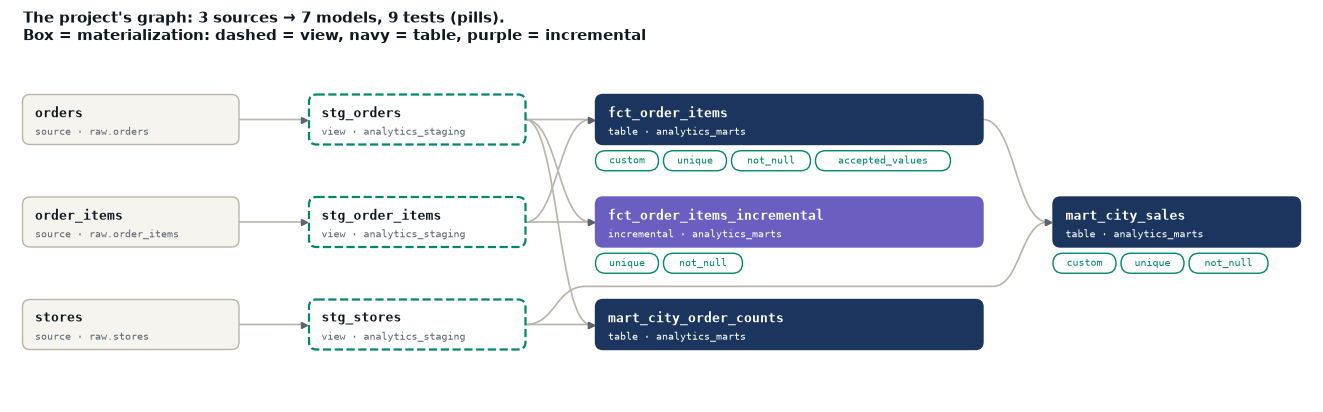

In [61]:
V.dbt_graph(PROJ)

**2 · The database dbt built**, compared with the one before its first run.

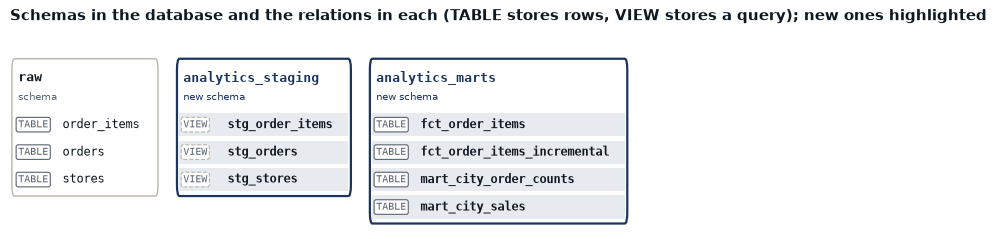

In [62]:
V.database_map(sql("SELECT table_schema, table_name, table_type FROM information_schema.tables"), before=tables_before)